# Compare Bond, Rittinger and Kick on one reduction

**Question:** Which energy-law assumptions explain the predicted work differences across the tested reduction range?

Level: 3. Prerequisites: Levels 1 and 2 in this topic. Reading time: 24 minutes.

## Objectives

Compare three comminution hypotheses over the same feed-size and product-size range, identify the calibration point at which they agree, and state what the comparison can and cannot establish.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 3 01-comminution lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow project authors; the nominal soft-porphyry case and work index are in `data/derived/cases/copper_porphyry_soft.json` (MIT project licence). Equations and comparison assumptions are transcribed in `docs/methodologies/09_energy.md`. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

Bond: $W=W_i(10/\sqrt{P}-10/\sqrt{F})$. Rittinger: $E=K_R(1/P-1/F)$; Kick: $E=K_K\ln(F/P)$. OreFlow calibrates $K_R$ and $K_K$ so all three match Bond at the declared 10,000 µm to 150 µm reference reduction. Away from that point they encode different size-reduction hypotheses. `law_curves` is the authoritative implementation used here.

## Comparison

Bond's work index is a standard-circuit empirical size-reduction method formalized in the Global Mining Guidelines Group's Bond Efficiency guideline (GMG01-MP-2021). Rittinger and Kick provide classical surface-area and reduction-ratio hypotheses; none is universally valid across every size regime. OreFlow reports Bond and keeps the other laws as diagnostic comparisons. This is a comparison of equations on an authored case, not a claim of superior prediction.

Load the OreFlow method and retrieve the case's documented work index and achieved size endpoints.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.energy import law_curves, reference_constants

# Use one consistent feed, work index and product-size sweep for all three laws.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")
record = json.loads(
    (repo / "data/derived/cases/copper_porphyry_soft.json").read_text(encoding="utf-8")
)
trace_record = record["variants"][0]["trace"]
metrics = trace_record["metrics"]
wi = case.nominal.work_index_kwh_t
f80 = metrics["crusher_feed_f80_um"]
print(
    "Wi (kWh/t):",
    wi,
    "| feed F80 (µm):",
    round(f80, 1),
    "| achieved P80 (µm):",
    round(metrics["p80_um"], 1),
)


Wi (kWh/t): 11.0 | feed F80 (µm): 60094.9 | achieved P80 (µm): 150.0


Calculate the three curves through OreFlow's shared method. The reference constants are calibrated once at the documented reference reduction.

In [3]:
# Evaluate the package implementation on a log-spaced, physically ordered size range.
p80 = np.geomspace(max(70.0, f80 / 30), f80 / 1.01, 80)
curves = law_curves(wi, f80, p80)
k_r, k_k = reference_constants(wi)
print("calibrated Rittinger constant:", k_r)
print("calibrated Kick constant:", k_k)
print(
    "Bond at reference 150 µm (kWh/t):",
    round(float(law_curves(wi, 10_000, np.array([150.0]))["bond"][0]), 3),
)


calibrated Rittinger constant: 1200.2226990159877
calibrated Kick constant: 1.8766704432930477
Bond at reference 150 µm (kWh/t): 7.881


Plot on the same axes. Because the x-axis is inverted, progressively finer products appear to the right; all three laws coincide at the reference point and diverge elsewhere.

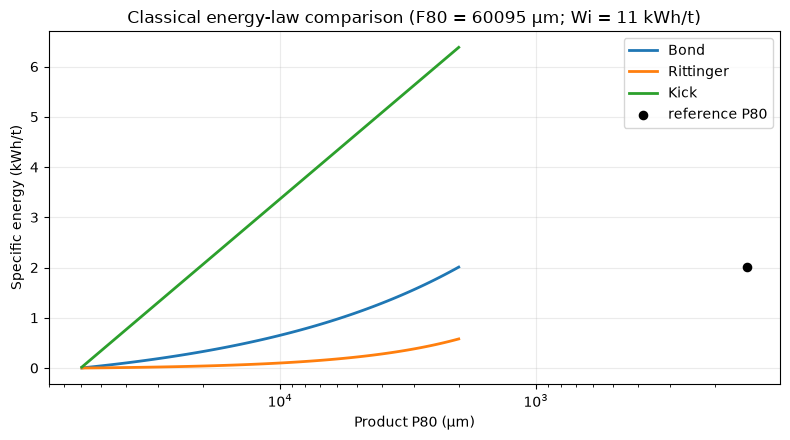

In [4]:
# Visualize the same feed and work index under all three calibrated laws.
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ("bond", "rittinger", "kick"):
    ax.plot(curves["p80_um"], curves[name], label=name.title(), linewidth=2)
ax.scatter(
    [150],
    [curves["bond"][int(np.argmin(abs(np.asarray(curves["p80_um"]) - 150)))]],
    s=35,
    color="black",
    zorder=3,
    label="reference P80",
)
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(
    xlabel="Product P80 (µm)",
    ylabel="Specific energy (kWh/t)",
    title=f"Classical energy-law comparison (F80 = {f80:.0f} µm; Wi = {wi:g} kWh/t)",
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()


Figure 14 in the level 3 01 comminution lesson reports outputs of independently solved operating points. For figure 14 in level 3 01 comminution, each mark is a separate model evaluation at its stated setting. For figure 14 in level 3 01 comminution, check recovery, size and energy against the contract limits. The line in figure 14 only guides comparison.

Quantify the spread at the actual case reduction. Interpret it as structural disagreement between hypotheses, not a confidence interval or observed plant error.

In [5]:
# Compare the three implemented values at this case's recorded product P80.
actual_p80 = float(metrics["p80_um"])
point = law_curves(wi, f80, np.array([actual_p80]))
comparison = pd.DataFrame(
    {
        "law": ["Bond", "Rittinger", "Kick"],
        "energy_kwh_t": [point["bond"][0], point["rittinger"][0], point["kick"][0]],
    }
)
comparison["relative_to_bond"] = comparison.energy_kwh_t / comparison.energy_kwh_t.iloc[0]
display(comparison)


,law,energy_kwh_t,relative_to_bond
0,Bond,8.532744,1.000000
1,Rittinger,7.981513,0.935398
2,Kick,11.246972,1.318095


In the level 3 01 comminution case, the 0.8× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 01 comminution case at 0.8× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


In the level 3 01 comminution case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 01 comminution case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


In the level 3 01 comminution case, the 1.0× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 01 comminution case at 1.0× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


In the level 3 01 comminution case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 01 comminution case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


In the level 3 01 comminution case, the 1.2× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 3 01 comminution case at 1.2× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


In the level 3 01 comminution lesson, plot reading 1 considers in this level 3 01 comminution plot, compare recovery with product P80 across the controlled throughput changes. In the level 3 01 comminution lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 3 01 comminution lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 3 01 comminution lesson, plot reading 4 considers for compare bond, rittinger and kick on one reduction, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

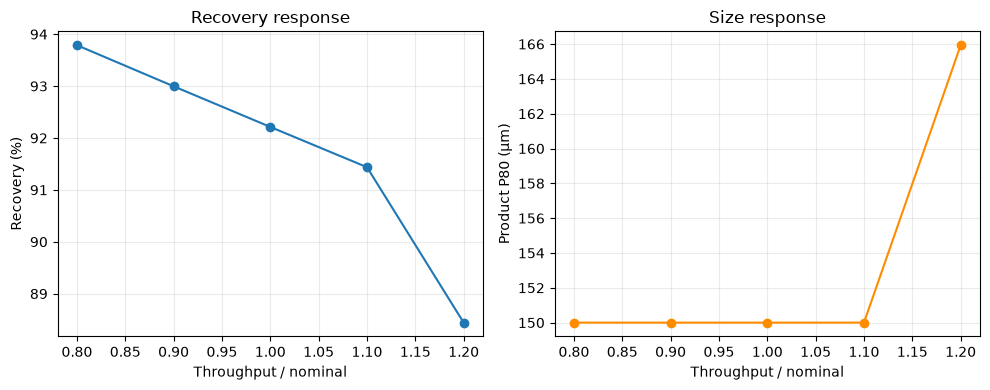

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 28 in the level 3 01 comminution lesson reports outputs of independently solved operating points. For figure 28 in level 3 01 comminution, each mark is a separate model evaluation at its stated setting. For figure 28 in level 3 01 comminution, check recovery, size and energy against the contract limits. The line in figure 28 only guides comparison.

At level 3 in 01 comminution, interpretation 1 is that comminution couples breakage, classification and recycle. At level 3 in 01 comminution, interpretation 2 is that a change in fresh feed can move the mill toward its installed-power limit, alter the size distribution entering the classifier and change circulating load. At level 3 in 01 comminution, interpretation 3 is that p80 alone does not describe the full distribution, so inspect the plotted cumulative curves and the engine's per-stream audit together. At level 3 in 01 comminution, interpretation 4 is that the Bond work-index equation is an empirical standard-circuit relation with a specified feed and product size basis. At level 3 in 01 comminution, interpretation 5 is that it is not a mechanistic law for every particle. At level 3 in 01 comminution, interpretation 6 is that rittinger and Kick express different scaling assumptions and should be compared at a common calibration point. At level 3 in 01 comminution, interpretation 7 is that a closed mass balance is necessary for a credible calculation, but it cannot establish that the breakage or selection parameters represent an operating plant. At level 3 in 01 comminution, interpretation 8 is that an independent validation would require measured feed and product size distributions, throughput, power and ore-specific calibration, with an agreed sampling protocol. At level 3 in 01 comminution, extension 1 shows that a useful validation table would align paired feed and product size classes with mill power and circulating load, because matching one percentile can hide a distribution error. At level 3 in 01 comminution, extension 2 shows that report the basis for moisture, density and work-index measurements, and state whether size values are mass or volume fractions. At level 3 in 01 comminution, extension 3 shows that the current circuit calculation is steady state, so a time sequence in the interface is a control sweep rather than a transient population balance.

## Results

**Answer:** In this level 3 01 comminution lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Compare Bond, Rittinger and Kick on one reduction.

The curves coincide by construction at the reference reduction; away from it, their spread reflects different functional forms. OreFlow uses Bond for its reported standard energy and does not sum the alternatives. The comparison has no measured plant-energy residual and cannot select the best law for a particular plant.

## Summary

A controlled same-case comparison makes the model choice visible: calibration makes laws agree at one point, not everywhere. Bond's stated fineness qualification and its energy basis still apply.

## References

- https://www.globalminingguidelines.org/guidelines/bond-efficiency/
- https://doi.org/10.1016/0301-7516(80)90034-4
- https://doi.org/10.1016/0301-7516(80)90034-4